# 07 · A Compact MLP with Learned Embeddings
**Owner:** Siraparapu Shiva Sankar Mani Kanta (2401010457) · Phase 2 rubric: **architecture logic**, **DL regularisation**, **theoretical rigour**

**Builds on:** notebook 06 (`dl_inputs.py`: encoder and sequences). **Commits:** `src/fdp/deep.py`, `reports/07_mlp.json`, `reports/figures/07_*.png`.

| Section | What it answers |
|---|---|
| A · Architecture logic | why this network, layer by layer |
| B · Training, and how it over-fits | loss curves with early stopping switched off |
| C · Regularisation | dropout, weight decay, early stopping, small size |
| D · Honest tuning on rolling months | the same protocol as Phase 1's boosting, with epochs instead of trees |
| E · What the embeddings learned | airports placed by behaviour, not by name |

⏱️ About 10–15 minutes on a Colab CPU (the search). `QUICK_RUN` ≈ 3 minutes. A GPU runtime is faster but not needed.

In [1]:
#@title ⚙️ 0 · Setup — run this cell first { display-mode: "form" }
#@markdown In **Colab** this clones the team repo and installs the requirements.
#@markdown Locally (Jupyter / VS Code) it just moves to the repo root.
REPO_URL = "https://github.com/RISHIK92/aml-project.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
QUICK_RUN = False  #@param {type:"boolean"}
#@markdown `QUICK_RUN` = smaller searches/samples so the notebook finishes in a few minutes (use it to check the code runs; turn it OFF for the final numbers you commit).

import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("/content/aml-project/.git"):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, "/content/aml-project"], check=True)
    os.chdir("/content/aml-project")
    if os.path.exists("requirements.txt"):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
for d in ["src/fdp", "tests", "data/raw", "data/processed", "reports/figures"]:
    os.makedirs(d, exist_ok=True)
open("src/fdp/__init__.py", "a").close()
sys.path.insert(0, os.path.abspath("src"))

import warnings; warnings.filterwarnings("ignore")
import torch; torch.set_num_threads(max(1, os.cpu_count() or 1))
import json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Working directory:", os.getcwd(), "| Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

Working directory: /tmp/fdp | Colab: False | QUICK_RUN: False


In [2]:
import fdp.config as config, fdp.data as data, fdp.features as features, fdp.dl_inputs as dl
df = data.build_dataset(*data.load_raw())
X, groups = features.build_features(df)
NUM, CAT = features.numeric_columns(groups), config.CATEGORICAL
S = data.split(X)
y = {k: v["delayed"].astype(int).to_numpy() for k, v in S.items()}

---
## A · Architecture logic
The brief asks for a **compact MLP with learned embeddings for airline, origin and destination**. Layer by layer:

```
numeric (42) ─────────────────────────────┐
carrier index → embedding table (16+2 rows × 7) ─┤
origin  index → embedding table ( 3+2 rows × 4)  ├─ concat → Linear → ReLU → Dropout → Linear → ReLU → Dropout → Linear → logit
dest    index → embedding table (~100 rows × 16) ┘                (hidden sizes chosen by the search in D)
```

* **Embedding:** each category owns a small vector of weights, learned by gradient descent like every other weight. One-hot gives every destination its own unrelated column; an embedding can place two airports that behave alike **close together**, so a rare destination borrows strength from similar ones (Guo & Berkhahn, 2016, *entity embeddings*).
* **Hidden layers + ReLU:** the non-linearity lets the network combine features (e.g. *evening* × *busy origin* × *bad yesterday*), which logistic regression cannot do without hand-made interaction terms. That is the gap named in the brief.
* **Output:** one **logit** z; the probability is σ(z). Training minimises **log loss** (binary cross-entropy), the same loss as logistic regression, so the two are directly comparable: logistic regression is this network with no hidden layer.
* **Why compact:** about 200,000 training rows and 44 inputs. A large network would memorise summer; the brief says compact, and Phase 1 already showed that capacity which fits summer does not transfer to autumn.
* **Optimiser:** AdamW (Adam with decoupled weight decay; Loshchilov & Hutter, 2019), mini-batches of 1,024 flights.

In [3]:
%%writefile src/fdp/deep.py
"""Phase 2 · the network, its training loop and the honest evaluation protocol.
Owner: Siraparapu Shiva Sankar Mani Kanta (Mani Kanta).

Three networks, all in one class so ablations switch parts on and off:
  MLP       numeric features + LEARNED EMBEDDINGS for carrier, origin, destination
  Temporal  + a GRU that reads the last 14 days of delay outcomes (dl_inputs.py)
  Hybrid    + logistic regression's logit as a fixed starting point: the network only learns
            a correction on top of LR (same idea as Phase 1's boosting-from-LR). The last layer
            starts at zero, so before training the hybrid IS logistic regression.
"""
import copy

import numpy as np
import torch
from sklearn.metrics import average_precision_score
from torch import nn

from .dl_inputs import emb_dim

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


# ----------------------------------------------------------------- network
class DelayNet(nn.Module):
    def __init__(self, n_num, cards, hidden=(256, 128), dropout=0.2, use_emb=True,
                 seq_channels=0, gru_hidden=32, use_offset=False):
        super().__init__()
        self.use_emb, self.use_seq, self.use_offset = use_emb, seq_channels > 0, use_offset
        if use_emb:
            self.embs = nn.ModuleList([nn.Embedding(n, emb_dim(n)) for n in cards])
            d_cat = sum(emb_dim(n) for n in cards)
        else:  # ablation: one-hot instead of learned embeddings
            self.cards = cards
            d_cat = sum(cards)
        if self.use_seq:
            self.gru = nn.GRU(seq_channels, gru_hidden, batch_first=True)
            d_seq = gru_hidden
        else:
            d_seq = 0
        layers, d = [], n_num + d_cat + d_seq
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d, 1)
        if use_offset:   # start exactly at logistic regression: correction = 0
            nn.init.zeros_(self.head.weight)
            nn.init.zeros_(self.head.bias)

    def forward(self, x_num, x_cat, seq=None, offset=None):
        parts = [x_num]
        if self.use_emb:
            parts += [e(x_cat[:, i]) for i, e in enumerate(self.embs)]
        else:
            parts += [nn.functional.one_hot(x_cat[:, i], n).float() for i, n in enumerate(self.cards)]
        if self.use_seq:
            _, h = self.gru(seq)          # h: last hidden state = a summary of the 14 days
            parts.append(h[-1])
        logit = self.head(self.body(torch.cat(parts, dim=1))).squeeze(1)
        if self.use_offset:
            logit = logit + offset
        return logit


# ----------------------------------------------------------------- training
def _batches(n, batch_size, shuffle, gen):
    idx = torch.randperm(n, generator=gen) if shuffle else torch.arange(n)
    for i in range(0, n, batch_size):
        yield idx[i:i + batch_size]


def _tensors(d):
    return {k: torch.as_tensor(v) for k, v in d.items() if v is not None}


def predict_logits(model, data, batch_size=4096):
    model.eval()
    t = _tensors(data)
    out = []
    with torch.no_grad():
        for b in _batches(len(t["x_num"]), batch_size, False, None):
            out.append(model(t["x_num"][b].to(DEVICE), t["x_cat"][b].to(DEVICE),
                             t["seq"][b].to(DEVICE) if "seq" in t else None,
                             t["offset"][b].to(DEVICE) if "offset" in t else None).cpu())
    return torch.cat(out).numpy()


def train(model, data, y, stop=None, y_stop=None, epochs=30, lr=1e-3, weight_decay=1e-4,
          batch_size=1024, patience=3, seed=42, verbose=False):
    """Mini-batch AdamW on log loss (BCE with logits).

    With a stop set: keep the epoch with the best stop-set PR AUC and stop after `patience`
    epochs without improvement (early stopping). Without one: run exactly `epochs` epochs.
    Returns (model, best_epoch, history)."""
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    t, yt = _tensors(data), torch.as_tensor(y, dtype=torch.float32)
    best, best_ep, best_state, hist, wait = -1.0, epochs, None, [], 0
    if stop is not None and getattr(model, "use_offset", False):
        # The hybrid starts as logistic regression (zero correction). Score that "epoch 0" too, so
        # early stopping can decide that NO correction transfers and keep plain LR.
        best = float(average_precision_score(y_stop, predict_logits(model, stop)))
        best_ep, best_state = 0, copy.deepcopy(model.state_dict())
        hist.append({"epoch": 0, "train_loss": float("nan"), "stop_pr_auc": best})
    for ep in range(1, epochs + 1):
        model.train()
        total = 0.0
        for b in _batches(len(yt), batch_size, True, gen):
            logit = model(t["x_num"][b].to(DEVICE), t["x_cat"][b].to(DEVICE),
                          t["seq"][b].to(DEVICE) if "seq" in t else None,
                          t["offset"][b].to(DEVICE) if "offset" in t else None)
            loss = loss_fn(logit, yt[b].to(DEVICE))
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(b)
        row = {"epoch": ep, "train_loss": total / len(yt)}
        if stop is not None:
            row["stop_pr_auc"] = float(average_precision_score(y_stop, predict_logits(model, stop)))
            if row["stop_pr_auc"] > best:
                best, best_ep, best_state, wait = row["stop_pr_auc"], ep, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
        hist.append(row)
        if verbose:
            print(row, flush=True)
        if stop is not None and wait >= patience:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_ep, hist


# ----------------------------------------------------------------- honest protocol
def prepare(frame, seq_all, numeric, categorical, fit_idx, idx_list, use_seq=False, use_offset=False,
            lr_C=0.001, offset_numeric=None):
    """Fit every statistic on frame.iloc[fit_idx] ONLY (encoder; logistic regression for the offset)
    and build model inputs for each index array in idx_list. Returns (inputs, n_num, cards).
    offset_numeric: the numeric columns logistic regression uses (default: the same as the network)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from .preprocess import linear_preprocessor
    from .dl_inputs import TabularEncoder
    fit = frame.iloc[fit_idx]
    enc = TabularEncoder(numeric, categorical).fit(fit)
    lr = None
    if use_offset:
        cols = list(offset_numeric or numeric) + list(categorical)
        lr_num = list(offset_numeric or numeric)
        lr = make_pipeline(linear_preprocessor(lr_num, categorical), LogisticRegression(C=lr_C, max_iter=3000))
        lr.fit(fit[cols], fit["delayed"].astype(int))
    out = []
    for idx in idx_list:
        part = frame.iloc[idx]
        x_num, x_cat = enc.transform(part)
        d = {"x_num": x_num, "x_cat": x_cat}
        if use_seq:
            d["seq"] = np.ascontiguousarray(seq_all[idx])
        if use_offset:
            d["offset"] = lr.decision_function(part[cols]).astype(np.float32)
        out.append(d)
    return out, out[0]["x_num"].shape[1], enc.cardinalities()


NET_KEYS = ("hidden", "dropout", "use_emb", "gru_hidden", "use_offset")
TRAIN_KEYS = ("lr", "weight_decay", "batch_size", "patience")


def build_net(cfg, n_num, cards, seq_channels):
    kw = {k: cfg[k] for k in NET_KEYS if k in cfg}
    return DelayNet(n_num, cards, seq_channels=seq_channels if cfg.get("use_seq") else 0, **kw)


def rolling_eval_nn(frame, seq_all, month, cfg, numeric, categorical, months=(7, 8, 9), seed=42, max_epochs=20,
                    offset_numeric=None):
    """Same honest protocol as Phase 1's boosting, with EPOCHS in place of trees. For month m:
      1. fit on months < m-1, early-stop on month m-1  -> best epoch count
      2. refit on all months < m for that many epochs
      3. score month m (never seen in steps 1-2).
    Returns (PR AUC per month, epochs per month)."""
    y = frame["delayed"].astype(int).to_numpy()
    tk = {k: cfg[k] for k in TRAIN_KEYS if k in cfg}
    C = seq_all.shape[2] if seq_all is not None else 0
    scores, epochs = [], []
    for m in months:
        inner, stop = np.where(month < m - 1)[0], np.where(month == m - 1)[0]
        full, test = np.where(month < m)[0], np.where(month == m)[0]
        (di, ds), n_num, cards = prepare(frame, seq_all, numeric, categorical, inner, [inner, stop],
                                          cfg.get("use_seq", False), cfg.get("use_offset", False),
                                          offset_numeric=offset_numeric)
        net = build_net(cfg, n_num, cards, C)
        _, ep, _ = train(net, di, y[inner], ds, y[stop], epochs=max_epochs, seed=seed, **tk)
        (df_, dt), n_num, cards = prepare(frame, seq_all, numeric, categorical, full, [full, test],
                                           cfg.get("use_seq", False), cfg.get("use_offset", False),
                                          offset_numeric=offset_numeric)
        net = build_net(cfg, n_num, cards, C)
        net, _, _ = train(net, df_, y[full], epochs=ep, seed=seed, **tk)
        scores.append(float(average_precision_score(y[test], predict_logits(net, dt))))
        epochs.append(int(ep))
    return scores, epochs

Overwriting src/fdp/deep.py


In [4]:
import fdp.deep as deep; importlib.reload(deep)
enc = dl.TabularEncoder(NUM, CAT).fit(S["train"])
D = {k: dict(zip(["x_num", "x_cat"], enc.transform(v))) for k, v in S.items()}
net = deep.DelayNet(D["train"]["x_num"].shape[1], enc.cardinalities(), hidden=(256, 128))
n_params = sum(p.numel() for p in net.parameters())
emb_params = sum(p.numel() for p in net.embs.parameters())
print(net)
print(f"trainable weights: {n_params:,} (of which embeddings: {emb_params:,})")

DelayNet(
  (embs): ModuleList(
    (0): Embedding(17, 8)
    (1): Embedding(5, 4)
    (2): Embedding(94, 16)
  )
  (body): Sequential(
    (0): Linear(in_features=70, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
  )
  (head): Linear(in_features=128, out_features=1, bias=True)
)
trainable weights: 52,861 (of which embeddings: 1,660)


---
## B · Training, and how it over-fits
First **without** early stopping: train on Jan 15 – Aug for a fixed number of epochs and watch September after each one. (September here is only a *watching* month; nothing is chosen from this plot.)

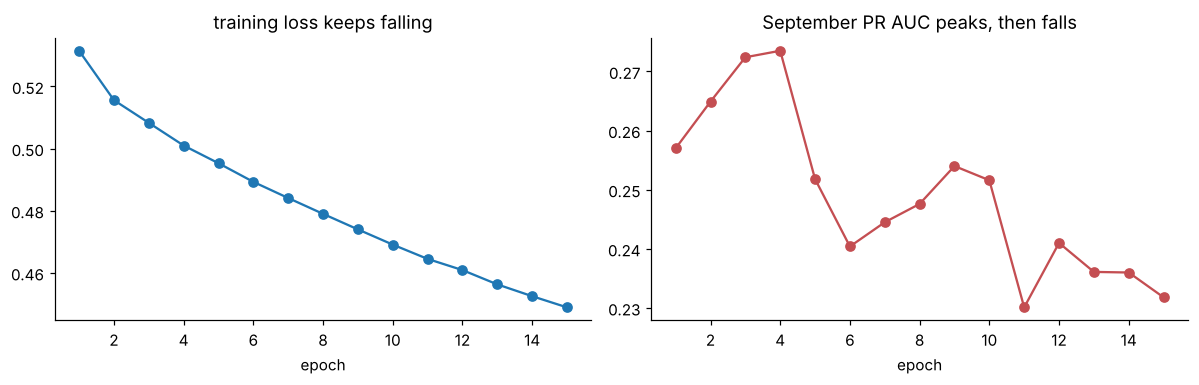

epoch,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
train log loss,0.5315,0.5156,0.5083,0.5010,0.4953,0.4893,0.4841,0.4790,0.474,0.4691,0.4645,0.4609,0.4563,0.4525,0.4489
September PR AUC,0.2570,0.2649,0.2724,0.2735,0.2518,0.2404,0.2445,0.2476,0.254,0.2516,0.2301,0.2410,0.2361,0.2360,0.2318


In [5]:
#@title 🎛️ Long run without early stopping { display-mode: "form" }
EPOCHS = 15  #@param {type:"slider", min:3, max:30, step:1}
if QUICK_RUN:
    EPOCHS = 5
from sklearn.metrics import average_precision_score as ap
curve = []
torch.manual_seed(config.SEED)
net = deep.DelayNet(D["train"]["x_num"].shape[1], enc.cardinalities(), hidden=(256, 128), dropout=0.0)
for ep in range(1, EPOCHS + 1):
    net, _, h = deep.train(net, D["train"], y["train"], epochs=1, weight_decay=0.0, seed=config.SEED + ep)
    curve.append({"epoch": ep, "train log loss": h[-1]["train_loss"],
                  "September PR AUC": ap(y["valid"], deep.predict_logits(net, D["valid"]))})
curve = pd.DataFrame(curve).set_index("epoch").round(4)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
curve["train log loss"].plot(ax=ax[0], marker="o", title="training loss keeps falling")
curve["September PR AUC"].plot(ax=ax[1], marker="o", color="#C44E52", title="September PR AUC peaks, then falls")
fig.tight_layout(); fig.savefig("reports/figures/07_overfitting.png"); plt.show()
curve.T

**Reading it:** the training loss falls every epoch, while September peaks after a few epochs and then drops: the network starts memorising **summer-specific** patterns. This is the bias–variance trade-off from Phase 1 again, now along the **epoch** axis instead of the tree-depth axis. Everything below is about stopping before that point.

---
## C · Regularisation
| Tool | What it does | Where |
|---|---|---|
| **Small network** | fewer weights = less room to memorise | `hidden` |
| **Dropout** | randomly zeroes a share of hidden units in each training step, so no unit can rely on one specific partner; at prediction time all units are used | `dropout` |
| **Weight decay (L2)** | shrinks every weight a little each step, the network version of logistic regression's C | `weight_decay` |
| **Early stopping** | keep the epoch with the best PR AUC on a held-out month; stop after 3 epochs without improvement | `patience` |
| **No re-sampling** | as in Phase 1: re-balancing the classes would bend the probabilities we need calibrated | — |

Early stopping hides the same trap Phase 1 found for boosting: if the stopping month is also the month you report, the score is optimistic. So the protocol is the same, with **epochs in place of trees**:
for month m → train on months before m−1, early-stop on m−1 (picks the epoch count) → refit on all months before m for that many epochs → score m.

---
## D · Honest tuning on rolling months
Same rolling months (Jul, Aug, Sep) and the same rule as Phase 1, so the numbers sit next to logistic regression's directly.

In [6]:
lab = pd.concat([S["train"], S["valid"]])
month = lab["date"].dt.month.to_numpy()
ylab = lab["delayed"].astype(int).to_numpy()
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
import fdp.preprocess as prep
lr_scores = []
for m in config.CV_MONTHS:
    tr, va = np.where(month < m)[0], np.where(month == m)[0]
    lr = make_pipeline(prep.linear_preprocessor(NUM, CAT), LogisticRegression(C=config.PHASE1_LR_C, max_iter=3000)).fit(lab.iloc[tr], ylab[tr])
    lr_scores.append(float(ap(ylab[va], lr.decision_function(lab.iloc[va]))))
print("logistic regression rolling PR AUC:", np.round(lr_scores, 4), "mean", round(float(np.mean(lr_scores)), 4))

logistic regression rolling PR AUC: [0.5565 0.4055 0.2655] mean 0.4092


In [7]:
#@title 🎛️ Random search over the MLP { display-mode: "form" }
N_ITER = 8  #@param {type:"slider", min:2, max:16, step:1}
if QUICK_RUN:
    N_ITER = 2
import itertools
GRID = {"hidden": [(256, 128), (64, 32)], "dropout": [0.2, 0.5], "lr": [1e-3, 3e-4], "weight_decay": [1e-4, 1e-2]}
combos = list(itertools.product(*GRID.values()))
picks = np.random.default_rng(config.SEED).choice(len(combos), N_ITER, replace=False)
rows = []
for i in picks:
    cfg = dict(zip(GRID, combos[i]))
    s, e = deep.rolling_eval_nn(lab, None, month, cfg, NUM, CAT, months=config.CV_MONTHS, seed=config.SEED)
    rows.append({**{k: str(v) for k, v in cfg.items()}, "Jul": s[0], "Aug": s[1], "Sep": s[2], "mean": float(np.mean(s)), "epochs per fold": e})
    print(rows[-1], flush=True)
search = pd.DataFrame(rows).sort_values("mean", ascending=False).reset_index(drop=True)
best_row = search.iloc[0]
BEST = {"hidden": eval(best_row["hidden"]), "dropout": float(best_row["dropout"]), "lr": float(best_row["lr"]), "weight_decay": float(best_row["weight_decay"])}
print("best:", BEST)
search.round(4)

{'hidden': '(256, 128)', 'dropout': '0.2', 'lr': '0.001', 'weight_decay': '0.01', 'Jul': 0.5581511977640378, 'Aug': 0.3963630899717451, 'Sep': 0.2550002666416889, 'mean': 0.4031715181258239, 'epochs per fold': [2, 2, 1]}


{'hidden': '(64, 32)', 'dropout': '0.2', 'lr': '0.0003', 'weight_decay': '0.01', 'Jul': 0.5555634730654027, 'Aug': 0.40422941178909655, 'Sep': 0.25369659287156937, 'mean': 0.4044964925753562, 'epochs per fold': [13, 8, 3]}


{'hidden': '(64, 32)', 'dropout': '0.5', 'lr': '0.001', 'weight_decay': '0.01', 'Jul': 0.5616765388443113, 'Aug': 0.3982097452750154, 'Sep': 0.25241178953929255, 'mean': 0.40409935788620643, 'epochs per fold': [4, 8, 2]}


{'hidden': '(64, 32)', 'dropout': '0.2', 'lr': '0.0003', 'weight_decay': '0.0001', 'Jul': 0.5552307932314696, 'Aug': 0.4042053648739538, 'Sep': 0.2537571210665174, 'mean': 0.40439775972398023, 'epochs per fold': [13, 8, 3]}


{'hidden': '(64, 32)', 'dropout': '0.5', 'lr': '0.001', 'weight_decay': '0.0001', 'Jul': 0.5610336187531874, 'Aug': 0.39924606762686893, 'Sep': 0.2515522717685752, 'mean': 0.4039439860495438, 'epochs per fold': [6, 8, 2]}


{'hidden': '(256, 128)', 'dropout': '0.5', 'lr': '0.001', 'weight_decay': '0.01', 'Jul': 0.5566438798172404, 'Aug': 0.4017364215873515, 'Sep': 0.2544107152075098, 'mean': 0.40426367220403386, 'epochs per fold': [4, 4, 1]}


{'hidden': '(256, 128)', 'dropout': '0.2', 'lr': '0.001', 'weight_decay': '0.0001', 'Jul': 0.5589643950972916, 'Aug': 0.40466931997077116, 'Sep': 0.25534471778353285, 'mean': 0.4063261442838652, 'epochs per fold': [2, 1, 1]}


{'hidden': '(256, 128)', 'dropout': '0.5', 'lr': '0.0003', 'weight_decay': '0.01', 'Jul': 0.5617122704245692, 'Aug': 0.4021217989485557, 'Sep': 0.2552633743171717, 'mean': 0.4063658145634322, 'epochs per fold': [8, 12, 2]}


best: {'hidden': (256, 128), 'dropout': 0.5, 'lr': 0.0003, 'weight_decay': 0.01}


,hidden,dropout,lr,weight_decay,Jul,Aug,Sep,mean,epochs per fold
0,"(256, 128)",0.5,0.0003,0.01,0.5617,0.4021,0.2553,0.4064,"[8, 12, 2]"
1,"(256, 128)",0.2,0.001,0.0001,0.5590,0.4047,0.2553,0.4063,"[2, 1, 1]"
2,"(64, 32)",0.2,0.0003,0.01,0.5556,0.4042,0.2537,0.4045,"[13, 8, 3]"
3,"(64, 32)",0.2,0.0003,0.0001,0.5552,0.4042,0.2538,0.4044,"[13, 8, 3]"
4,"(256, 128)",0.5,0.001,0.01,0.5566,0.4017,0.2544,0.4043,"[4, 4, 1]"
5,"(64, 32)",0.5,0.001,0.01,0.5617,0.3982,0.2524,0.4041,"[4, 8, 2]"
6,"(64, 32)",0.5,0.001,0.0001,0.5610,0.3992,0.2516,0.4039,"[6, 8, 2]"
7,"(256, 128)",0.2,0.001,0.01,0.5582,0.3964,0.2550,0.4032,"[2, 2, 1]"


**What the search shows:**
* All settings land within a few thousandths of each other, **and all sit at or just below logistic regression's rolling score**. A network that can learn interactions does not beat the linear model on these 44 inputs. That repeats Phase 1's finding for boosting, now for a different model family.
* The chosen **epoch counts are small and jump between folds** (often 1–4 when the stopping month is August or September): what the network learns beyond the first epochs does not carry over to the next month.
* Larger dropout and weight decay need **more** epochs before over-fitting, which is what regularisation should do.

The next notebook asks whether the part the brief calls optional, the **ordered history**, changes this.

---
## E · What the embeddings learned
Train one MLP with the best settings on Jan 15 – Aug (early stop on September), then look at the **destination embedding table**. Each destination is a point in a 16-number space; PCA squeezes it to two numbers for plotting. Colour = the destination's late rate in training (the network was **not** given this number directly).

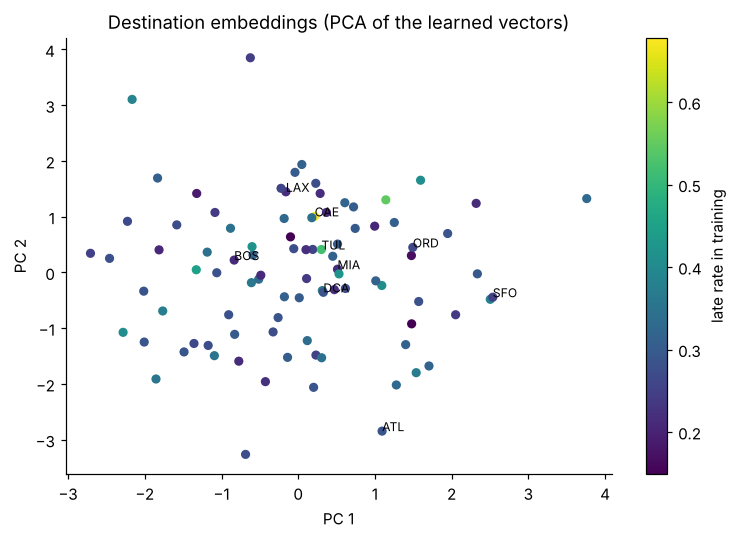

best epoch on September: 20 | correlation of PC 1 with the training late rate: 0.01


In [8]:
torch.manual_seed(config.SEED)
net = deep.DelayNet(D["train"]["x_num"].shape[1], enc.cardinalities(), hidden=BEST["hidden"], dropout=BEST["dropout"])
net, best_ep, hist = deep.train(net, D["train"], y["train"], D["valid"], y["valid"], epochs=20, lr=BEST["lr"], weight_decay=BEST["weight_decay"], seed=config.SEED)
W = net.embs[2].weight.detach().cpu().numpy()
inv = {i: v for v, i in enc.vocab["dest"].items()}
rate = S["train"].groupby("dest")["delayed"].mean()
pts = pd.DataFrame([(inv[i], *W[i]) for i in inv], columns=["dest"] + [f"e{j}" for j in range(W.shape[1])]).set_index("dest")
from sklearn.decomposition import PCA
xy = PCA(2, random_state=0).fit_transform(pts.to_numpy())
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(xy[:, 0], xy[:, 1], c=rate.reindex(pts.index), cmap="viridis", s=25)
for name in ["ATL", "ORD", "LAX", "SFO", "BOS", "MIA", "DCA", "CAE", "TUL"]:
    if name in pts.index:
        j = pts.index.get_loc(name); ax.annotate(name, xy[j], fontsize=8)
plt.colorbar(sc, label="late rate in training"); ax.set(title="Destination embeddings (PCA of the learned vectors)", xlabel="PC 1", ylabel="PC 2")
fig.tight_layout(); fig.savefig("reports/figures/07_dest_embeddings.png"); plt.show()
corr = float(np.corrcoef(xy[:, 0], rate.reindex(pts.index))[0, 1])
print(f"best epoch on September: {best_ep} | correlation of PC 1 with the training late rate: {corr:.2f}")

If the first principal component lines up with the late rate, the network has organised airports by **how they behave**, from the labels alone. That is what "learned representation" means in practice, and why embeddings can help a rare airport: it sits next to airports with more data. If the correlation printed above is **weak**, say so: each destination's late rate is already given to the network through the history features, so the embedding has little reason to re-learn it and may encode other structure. Do not claim more than the number shows.

In [9]:
out = {"n_params": int(n_params), "emb_params": int(emb_params), "overfit_curve": curve.reset_index().to_dict(orient="records"),
       "lr_rolling": lr_scores, "lr_rolling_mean": float(np.mean(lr_scores)),
       "search": search.to_dict(orient="records"), "best": {k: (list(v) if isinstance(v, tuple) else v) for k, v in BEST.items()},
       "embedding_best_epoch": int(best_ep), "embedding_pc1_corr": corr, "quick_run": QUICK_RUN}
with open("reports/07_mlp.json", "w") as f:
    json.dump(out, f, indent=2, default=str)
print("saved reports/07_mlp.json")

saved reports/07_mlp.json


<details><summary><b>Viva questions for this notebook (click)</b></summary>

1. **What is an embedding, and how is it trained?** A table with one small weight vector per category; the category's index selects its row; the rows are updated by back-propagation like any weight.
2. **Embedding vs one-hot?** One-hot = one unrelated column per category (100 destinations = 100 columns, rare ones barely trained). An embedding is dense and low-dimensional, and similar categories end up close, so rare ones borrow strength.
3. **How is logistic regression related to this network?** It is the same model with no hidden layer: a weighted sum, a sigmoid, log loss. The hidden layers add interactions.
4. **Why ReLU?** Without a non-linearity, stacked linear layers collapse into one linear layer. ReLU is cheap and does not saturate for positive inputs, so gradients flow.
5. **What does dropout do at training vs prediction time?** Training: zeroes a random share of units each step (and scales the rest). Prediction: uses all units. It stops units co-adapting, a cheap form of averaging many thinner networks.
6. **Weight decay vs C in logistic regression?** Both are L2 penalties on the weights; larger weight decay = smaller C = stronger shrinkage.
7. **Why early-stop on the month before, not on the month you report?** The stopping rule would see the answers and the score would be optimistic: the trap Phase 1 measured for boosting (+0.020).
8. **Did the MLP beat logistic regression?** No: on rolling months every setting is at or just below LR. That is a finding, not a failure: on these features, the interactions an MLP can learn do not transfer from one month to the next.
9. **Why is the network "compact"?** ~200k rows, 44 inputs; the brief asks for compact, and Phase 1 showed extra capacity fits summer, not autumn.
</details>

In [10]:
#@title 📦 Last step · download the files you must commit { display-mode: "form" }
#@markdown Downloads a zip with your module(s) and results. Also do **File → Download → Download .ipynb** (keeps the outputs).
#@markdown Unzip both into your local clone of the repo and commit them as shown in the team guide.
import glob, zipfile
FILES = [
    'src/fdp/deep.py',
    'reports/07_mlp.json',
    'reports/figures/07_*.png',
]
paths = sorted({p for pattern in FILES for p in glob.glob(pattern)})
zip_name = "07_outputs.zip"
with zipfile.ZipFile(zip_name, "w") as z:
    for p in paths:
        z.write(p)
print("Packed", len(paths), "files into", zip_name)
for p in paths:
    print("  ", p)
if IN_COLAB:
    from google.colab import files
    files.download(zip_name)

Packed 4 files into 07_outputs.zip
   reports/07_mlp.json
   reports/figures/07_dest_embeddings.png
   reports/figures/07_overfitting.png
   src/fdp/deep.py
